# Laboratorio 06: Modelos de Clasificación y Predicción (Regresión)

**Objetivo:** Desarrollar e implementar dos pipelines completos de Machine Learning en un único notebook:
1. **Tarea 1: Modelo de Clasificación** con el conjunto de datos *Heart Disease*.
2. **Tarea 2: Modelo de Predicción (Regresión)** con el conjunto de datos *California Housing Prices*.

Cada tarea incluye:
- Carga y análisis exploratorio de datos (EDA).
- Preprocesamiento y escalamiento de características.
- Partición de datos (Train/Test) y validación cruzada (*Cross-Validation*).
- Entrenamiento de 4 algoritmos de Machine Learning (incluyendo obligatoriamente un **MLP**).
- Comparación cuantitativa mediante múltiples métricas y selección del mejor modelo.
- Evaluación diagnóstica final sobre el conjunto de test independiente.


## 0. Configuración del Entorno y Librerías

Importación de bibliotecas científicas y definición de la semilla global (`RANDOM_STATE = 42`) para garantizar reproducibilidad en todas las particiones y modelos.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Configuración de advertencias y estilo visual
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Semilla global de reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Entorno configurado correctamente.")


Entorno configurado correctamente.


---
# PARTE 1: Tarea de Clasificación (Heart Disease Dataset)

El objetivo es predecir la presencia (`target=1`) o ausencia (`target=0`) de enfermedad cardíaca a partir de 13 variables clínicas y demográficas de pacientes.

---
### 1.1 Carga y Exploración Inicial del Dataset (EDA)
Cargamos los datos, verificamos tipos, valores nulos y la distribución de la variable objetivo.


In [2]:
# Carga del dataset de clasificación
df_clf = pd.read_csv('data/heart.csv')

print(f"Dimensiones del dataset: {df_clf.shape[0]} filas x {df_clf.shape[1]} columnas")
print(f"Valores nulos totales: {df_clf.isnull().sum().sum()}")
df_clf.head()


Dimensiones del dataset: 303 filas x 14 columnas
Valores nulos totales: 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


### 1.2 Análisis de Distribución y Correlación
Examinamos el balance entre clases y la correlación de las características con el target.


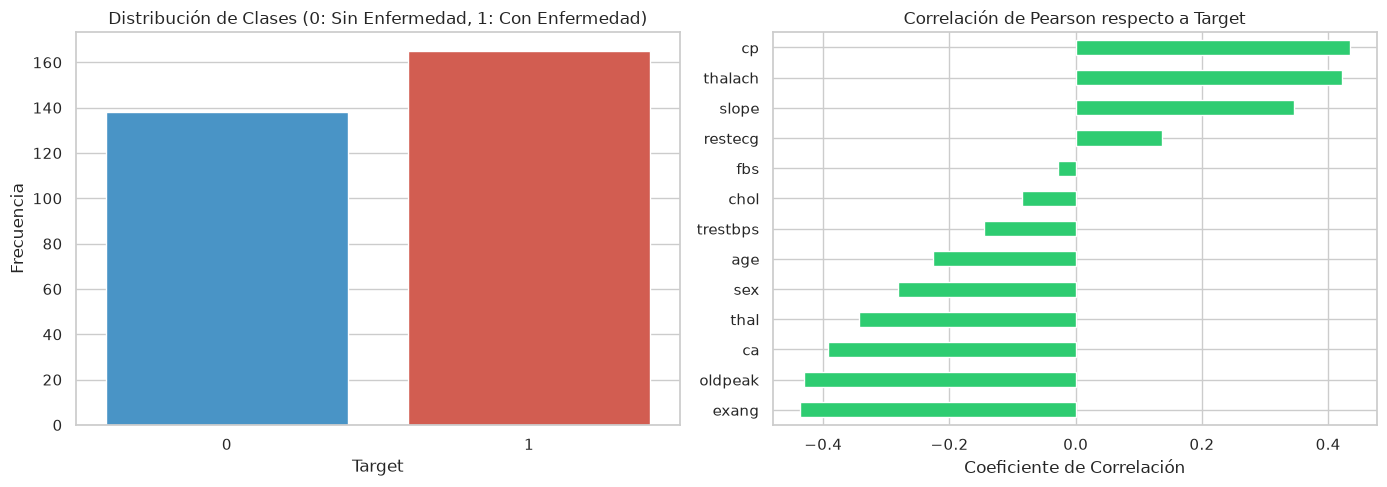

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Distribución de clases
sns.countplot(data=df_clf, x='target', ax=axes[0], palette=['#3498db', '#e74c3c'])
axes[0].set_title('Distribución de Clases (0: Sin Enfermedad, 1: Con Enfermedad)')
axes[0].set_xlabel('Target')
axes[0].set_ylabel('Frecuencia')

# 2. Correlación de variables con el target
corr_target = df_clf.corr()['target'].drop('target').sort_values()
corr_target.plot(kind='barh', ax=axes[1], color='#2ecc71')
axes[1].set_title('Correlación de Pearson respecto a Target')
axes[1].set_xlabel('Coeficiente de Correlación')

plt.tight_layout()
plt.show()


### 1.3 Preprocesamiento, Partición Train/Test y Validación Cruzada
- **División:** 80% Entrenamiento y 20% Prueba (*Hold-out Test*) con estratificación.
- **Escalamiento:** Estandarización (`StandardScaler`) ajustada únicamente sobre Train para evitar fuga de información (*data leakage*).
- **Validación Cruzada:** `StratifiedKFold` con 5 folds.


In [4]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler

# Separación de características y variable objetivo
X_clf = df_clf.drop(columns=['target'])
y_clf = df_clf['target']

# Partición Train (80%) / Test (20%) estratificada
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=RANDOM_STATE, stratify=y_clf
)

# Pipeline de escalamiento (crítico para MLP y SVM)
scaler_c = StandardScaler()
X_train_c_scaled = scaler_c.fit_transform(X_train_c)
X_test_c_scaled = scaler_c.transform(X_test_c)

# Estrategia de Cross-Validation (5 Folds Estratificados)
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Conjunto de Entrenamiento: {X_train_c_scaled.shape[0]} muestras")
print(f"Conjunto de Test (Hold-out): {X_test_c_scaled.shape[0]} muestras")


Conjunto de Entrenamiento: 242 muestras
Conjunto de Test (Hold-out): 61 muestras


### 1.4 Definición y Entrenamiento de los 4 Modelos de Clasificación
Seleccionamos 4 modelos con diferentes paradigmas de aprendizaje:
1. **Multi-Layer Perceptron (`MLPClassifier` - Requerido):** Red neuronal feedforward de 2 capas ocultas `(64, 32)` con regularización L2.
2. **Random Forest (`RandomForestClassifier`):** Ensamble tipo Bagging con árboles de decisión.
3. **Gradient Boosting (`GradientBoostingClassifier`):** Ensamble secuencial tipo Boosting.
4. **Support Vector Classifier (`SVC`):** Clasificador de vectores de soporte con kernel no lineal RBF.


In [5]:
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

# Diccionario con los 4 modelos de clasificación
clf_models = {
    'MLP (Multi-Layer Perceptron)': MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        alpha=0.01,
        max_iter=600,
        random_state=RANDOM_STATE
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=150,
        max_depth=6,
        random_state=RANDOM_STATE
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.08,
        max_depth=3,
        random_state=RANDOM_STATE
    ),
    'Support Vector Machine (SVC)': SVC(
        kernel='rbf',
        C=1.0,
        probability=True,
        random_state=RANDOM_STATE
    )
}

# Métricas para evaluación en Cross-Validation
scoring_clf = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'roc_auc']

clf_cv_results = {}
for name, model in clf_models.items():
    scores = cross_validate(model, X_train_c_scaled, y_train_c, cv=cv_clf, scoring=scoring_clf, n_jobs=-1)
    clf_cv_results[name] = {
        'Accuracy': scores['test_accuracy'].mean(),
        'Accuracy_Std': scores['test_accuracy'].std(),
        'F1-Score': scores['test_f1_macro'].mean(),
        'F1_Std': scores['test_f1_macro'].std(),
        'Precision': scores['test_precision_macro'].mean(),
        'Recall': scores['test_recall_macro'].mean(),
        'ROC-AUC': scores['test_roc_auc'].mean(),
        'ROC_AUC_Std': scores['test_roc_auc'].std()
    }

# Construcción de tabla resumen
df_clf_results = pd.DataFrame(clf_cv_results).T
df_clf_results.sort_values(by='F1-Score', ascending=False)


,Accuracy,Accuracy_Std,F1-Score,F1_Std,Precision,Recall,ROC-AUC,ROC_AUC_Std
Random Forest,0.822279,0.059512,0.819646,0.060817,0.823064,0.818972,0.880976,0.060995
Support Vector Machine (SVC),0.797449,0.061136,0.794387,0.062759,0.798572,0.793939,0.876910,0.047825
MLP (Multi-Layer Perceptron),0.781207,0.026054,0.778477,0.026242,0.781441,0.778140,0.869231,0.016429
Gradient Boosting,0.760459,0.098537,0.756010,0.101550,0.760823,0.756112,0.838462,0.064321


### 1.5 Comparativa de Métricas y Selección del Mejor Modelo de Clasificación
Visualizamos el rendimiento promedio obtenido en Cross-Validation para determinar el mejor algoritmo clasificador.


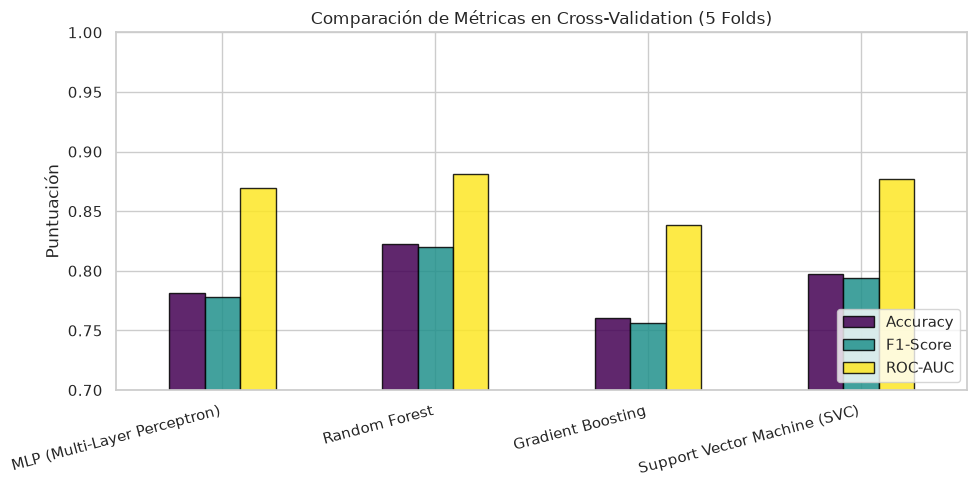

--> Modelo Ganador Seleccionado: Random Forest
    F1-Score CV: 0.8196 ± 0.0608
    ROC-AUC CV:  0.8810 ± 0.0610


In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
metrics_plot = df_clf_results[['Accuracy', 'F1-Score', 'ROC-AUC']]
metrics_plot.plot(kind='bar', ax=ax, colormap='viridis', edgecolor='black', alpha=0.85)

ax.set_title('Comparación de Métricas en Cross-Validation (5 Folds)')
ax.set_ylabel('Puntuación')
ax.set_ylim([0.7, 1.0])
plt.xticks(rotation=15, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# Selección automática del mejor modelo basado en F1-Score
best_clf_name = df_clf_results['F1-Score'].idxmax()
best_clf_model = clf_models[best_clf_name]
print(f"--> Modelo Ganador Seleccionado: {best_clf_name}")
print(f"    F1-Score CV: {df_clf_results.loc[best_clf_name, 'F1-Score']:.4f} ± {df_clf_results.loc[best_clf_name, 'F1_Std']:.4f}")
print(f"    ROC-AUC CV:  {df_clf_results.loc[best_clf_name, 'ROC-AUC']:.4f} ± {df_clf_results.loc[best_clf_name, 'ROC_AUC_Std']:.4f}")


### 1.6 Evaluación Final en Test y Rendimiento del Modelo de Clasificación
Entrenamos el modelo seleccionado con todo el conjunto de entrenamiento (`X_train`) y medimos su generalización real en el conjunto de prueba (`X_test`), presentando la **Matriz de Confusión**, el **Reporte de Clasificación** y la **Curva ROC**.


=== REPORTE DE CLASIFICACIÓN EN TEST: Random Forest ===
                    precision    recall  f1-score   support

Sin Enfermedad (0)     0.9524    0.7143    0.8163        28
Con Enfermedad (1)     0.8000    0.9697    0.8767        33

          accuracy                         0.8525        61
         macro avg     0.8762    0.8420    0.8465        61
      weighted avg     0.8699    0.8525    0.8490        61



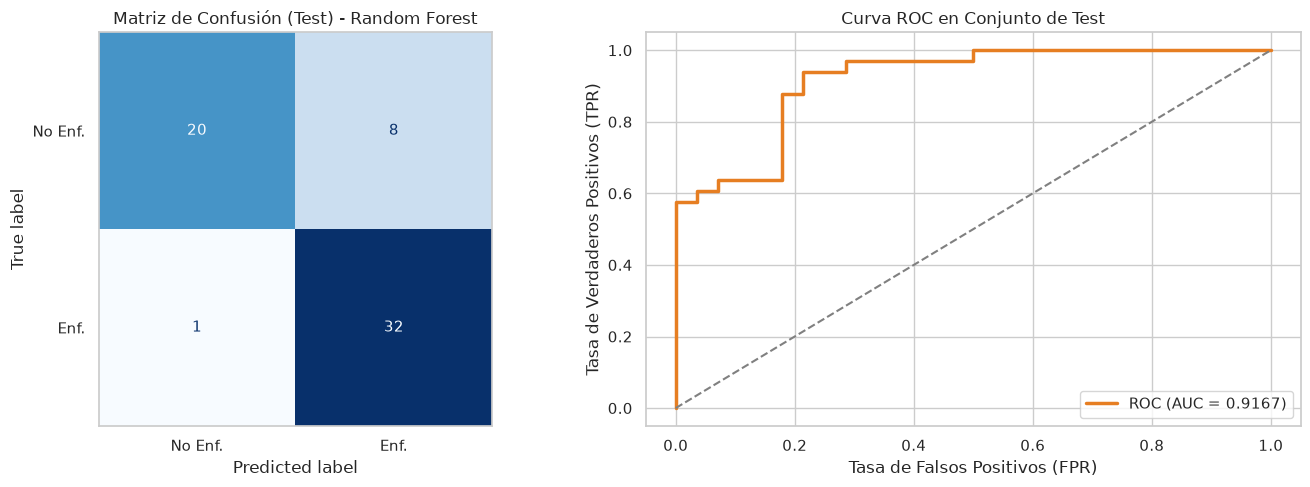

In [7]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

# Entrenamiento final en el conjunto de Train completo
best_clf_model.fit(X_train_c_scaled, y_train_c)

# Predicciones y probabilidades en Test
y_pred_c = best_clf_model.predict(X_test_c_scaled)
y_prob_c = best_clf_model.predict_proba(X_test_c_scaled)[:, 1]

# 1. Reporte de Clasificación
print(f"=== REPORTE DE CLASIFICACIÓN EN TEST: {best_clf_name} ===")
print(classification_report(y_test_c, y_pred_c, target_names=['Sin Enfermedad (0)', 'Con Enfermedad (1)'], digits=4))

# 2. Visualización: Matriz de Confusión y Curva ROC
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de Confusión
cm = confusion_matrix(y_test_c, y_pred_c)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Enf.', 'Enf.'])
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Matriz de Confusión (Test) - {best_clf_name}')
axes[0].grid(False)

# Curva ROC
fpr, tpr, _ = roc_curve(y_test_c, y_prob_c)
roc_score = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='#e67e22', lw=2.5, label=f'ROC (AUC = {roc_score:.4f})')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[1].set_xlabel('Tasa de Falsos Positivos (FPR)')
axes[1].set_ylabel('Tasa de Verdaderos Positivos (TPR)')
axes[1].set_title('Curva ROC en Conjunto de Test')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()


---
# PARTE 2: Tarea de Predicción (Regresión - California Housing Prices)

El objetivo es predecir el valor medio de las viviendas (`MedHouseVal` en cientos de miles de USD) para distritos residenciales de California a partir de variables demográficas, socioeconómicas y geográficas.

---
### 2.1 Carga y Exploración Inicial del Dataset (EDA)
Cargamos el dataset, evaluamos distribución de la variable continua y relaciones clave.


In [8]:
# Carga del dataset de regresión
df_reg = pd.read_csv('data/housing.csv')

print(f"Dimensiones del dataset: {df_reg.shape[0]} filas x {df_reg.shape[1]} columnas")
print(f"Valores nulos totales: {df_reg.isnull().sum().sum()}")
df_reg.head()


Dimensiones del dataset: 20640 filas x 9 columnas
Valores nulos totales: 0


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


### 2.2 Análisis de Distribución de la Variable Objetivo y Matriz de Correlación
Examinamos la distribución de `MedHouseVal` y su correlación con predictores principales como `MedInc` (Ingreso Mediano).


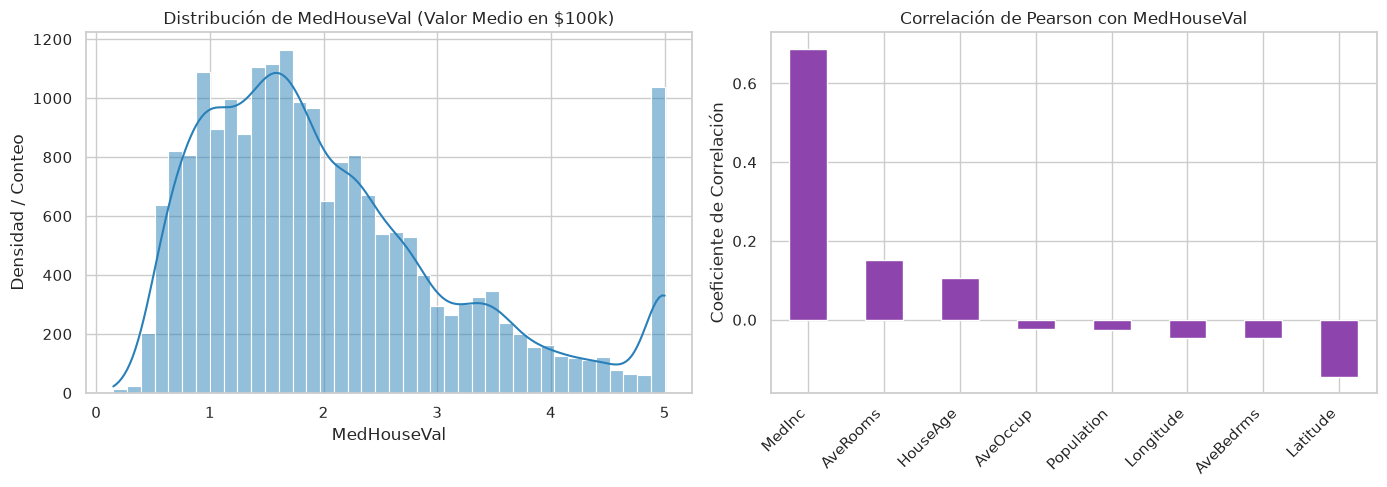

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Distribución del valor medio de vivienda
sns.histplot(df_reg['MedHouseVal'], kde=True, ax=axes[0], color='#2980b9', bins=40)
axes[0].set_title('Distribución de MedHouseVal (Valor Medio en $100k)')
axes[0].set_xlabel('MedHouseVal')
axes[0].set_ylabel('Densidad / Conteo')

# 2. Correlaciones con MedHouseVal
corr_reg = df_reg.corr()['MedHouseVal'].drop('MedHouseVal').sort_values(ascending=False)
corr_reg.plot(kind='bar', ax=axes[1], color='#8e44ad')
axes[1].set_title('Correlación de Pearson con MedHouseVal')
axes[1].set_ylabel('Coeficiente de Correlación')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()


### 2.3 Preprocesamiento, Partición Train/Test y Validación Cruzada
- **División:** 80% Entrenamiento y 20% Prueba (*Hold-out Test*).
- **Escalamiento:** Normalización con `StandardScaler` ajustado sobre `X_train_r` para garantizar estabilidad de optimización en el MLP y modelos basados en gradientes.
- **Validación Cruzada:** `KFold` de 5 particiones aleatorias barajadas.


In [10]:
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

# Separación de características y variable dependiente
X_reg = df_reg.drop(columns=['MedHouseVal'])
y_reg = df_reg['MedHouseVal']

# Partición Train (80%) y Test (20%)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE
)

# Escalamiento de características
scaler_r = StandardScaler()
X_train_r_scaled = scaler_r.fit_transform(X_train_r)
X_test_r_scaled = scaler_r.transform(X_test_r)

# Esquema de validación cruzada para regresión
cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Conjunto de Entrenamiento: {X_train_r_scaled.shape[0]} muestras")
print(f"Conjunto de Test (Hold-out): {X_test_r_scaled.shape[0]} muestras")


Conjunto de Entrenamiento: 16512 muestras
Conjunto de Test (Hold-out): 4128 muestras


### 2.4 Definición y Entrenamiento de los 4 Modelos de Predicción (Regresión)
Seleccionamos 4 regresores de distintas familias:
1. **Multi-Layer Perceptron Regressor (`MLPRegressor` - Requerido):** Red neuronal para aproximación no lineal con 2 capas ocultas `(64, 32)`.
2. **Random Forest Regressor (`RandomForestRegressor`):** Ensamble tipo Bagging no lineal.
3. **Gradient Boosting Regressor (`HistGradientBoostingRegressor`):** Ensamble Boosting optimizado de alto desempeño.
4. **Ridge Regression (`Ridge`):** Modelo de regresión lineal con regularización $L_2$ (*Baseline*).


In [11]:
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge

# Diccionario con los 4 modelos de regresión
reg_models = {
    'MLP (Multi-Layer Perceptron)': MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        alpha=0.01,
        max_iter=500,
        early_stopping=True,
        random_state=RANDOM_STATE
    ),
    'Random Forest Regressor': RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),
    'Hist Gradient Boosting': HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.08,
        max_depth=8,
        random_state=RANDOM_STATE
    ),
    'Ridge Regression (L2)': Ridge(
        alpha=1.0,
        random_state=RANDOM_STATE
    )
}

# Métricas para evaluación en Cross-Validation
scoring_reg = {
    'R2': 'r2',
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'MSE': 'neg_mean_squared_error'
}

reg_cv_results = {}
for name, model in reg_models.items():
    scores = cross_validate(model, X_train_r_scaled, y_train_r, cv=cv_reg, scoring=scoring_reg, n_jobs=-1)
    reg_cv_results[name] = {
        'R2_Score': scores['test_R2'].mean(),
        'R2_Std': scores['test_R2'].std(),
        'RMSE': -scores['test_RMSE'].mean(),
        'RMSE_Std': scores['test_RMSE'].std(),
        'MAE': -scores['test_MAE'].mean(),
        'MAE_Std': scores['test_MAE'].std(),
        'MSE': -scores['test_MSE'].mean()
    }

# Construcción de tabla comparativa
df_reg_results = pd.DataFrame(reg_cv_results).T
df_reg_results.sort_values(by='R2_Score', ascending=False)


,R2_Score,R2_Std,RMSE,RMSE_Std,MAE,MAE_Std,MSE
Hist Gradient Boosting,0.834504,0.006453,0.470282,0.013471,0.313637,0.007816,0.221347
Random Forest Regressor,0.795394,0.006233,0.522901,0.011750,0.348415,0.006033,0.273564
MLP (Multi-Layer Perceptron),0.785683,0.007214,0.535112,0.010704,0.363557,0.008121,0.286459
Ridge Regression (L2),0.611457,0.012357,0.720509,0.013895,0.529056,0.009381,0.519326


### 2.5 Comparativa de Métricas y Selección del Mejor Modelo de Regresión
Evaluamos el coeficiente de determinación $R^2$ (a mayor valor, mejor ajuste) y el error $RMSE$ (a menor valor, menor desviación).


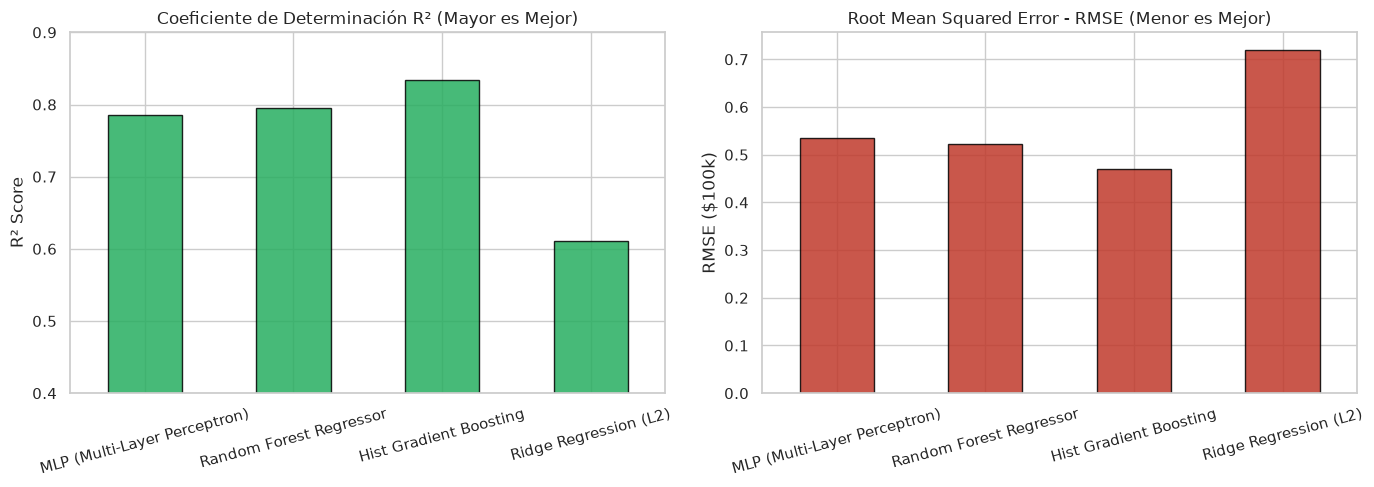

--> Modelo Ganador Seleccionado: Hist Gradient Boosting
    R² Score CV: 0.8345 ± 0.0065
    RMSE CV:     0.4703 ± 0.0135
    MAE CV:      0.3136 ± 0.0078


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Gráfico de R2 Score
df_reg_results['R2_Score'].plot(kind='bar', ax=axes[0], color='#27ae60', edgecolor='black', alpha=0.85)
axes[0].set_title('Coeficiente de Determinación R² (Mayor es Mejor)')
axes[0].set_ylabel('R² Score')
axes[0].set_ylim([0.4, 0.9])
axes[0].tick_params(axis='x', rotation=15)

# 2. Gráfico de RMSE
df_reg_results['RMSE'].plot(kind='bar', ax=axes[1], color='#c0392b', edgecolor='black', alpha=0.85)
axes[1].set_title('Root Mean Squared Error - RMSE (Menor es Mejor)')
axes[1].set_ylabel('RMSE ($100k)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

# Selección del mejor modelo según mayor R2
best_reg_name = df_reg_results['R2_Score'].idxmax()
best_reg_model = reg_models[best_reg_name]
print(f"--> Modelo Ganador Seleccionado: {best_reg_name}")
print(f"    R² Score CV: {df_reg_results.loc[best_reg_name, 'R2_Score']:.4f} ± {df_reg_results.loc[best_reg_name, 'R2_Std']:.4f}")
print(f"    RMSE CV:     {df_reg_results.loc[best_reg_name, 'RMSE']:.4f} ± {df_reg_results.loc[best_reg_name, 'RMSE_Std']:.4f}")
print(f"    MAE CV:      {df_reg_results.loc[best_reg_name, 'MAE']:.4f} ± {df_reg_results.loc[best_reg_name, 'MAE_Std']:.4f}")


### 2.6 Evaluación Final en Test y Rendimiento del Modelo de Regresión
Entrenamos el modelo seleccionado con la totalidad de `X_train_r` y computamos las métricas sobre el conjunto de test independiente (`X_test_r`), complementando con gráficos de dispersión de **Valores Reales vs. Predichos** y **Distribución de Residuos**.


=== RENDIMIENTO EN TEST: Hist Gradient Boosting ===
  R² Score (Test):                0.8387
  RMSE (Root Mean Squared Error):  0.4597
  MAE (Mean Absolute Error):       0.3076
  MSE (Mean Squared Error):        0.2113


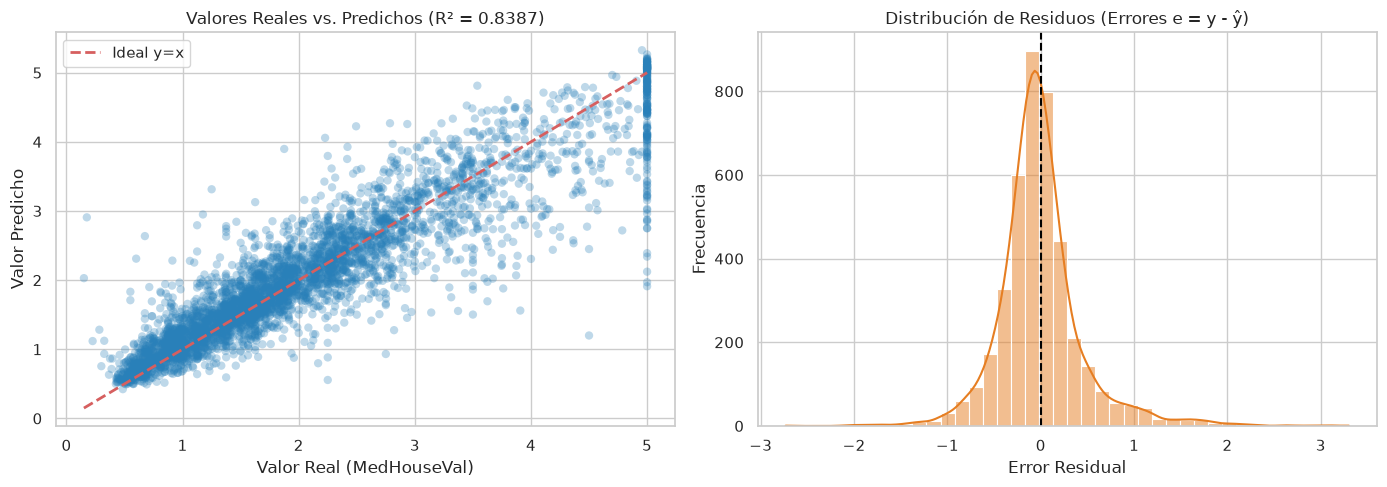

In [13]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Entrenamiento final en el conjunto Train completo
best_reg_model.fit(X_train_r_scaled, y_train_r)

# Predicciones sobre el conjunto Test
y_pred_r = best_reg_model.predict(X_test_r_scaled)

# Cálculo de métricas de test
test_r2 = r2_score(y_test_r, y_pred_r)
test_rmse = np.sqrt(mean_squared_error(y_test_r, y_pred_r))
test_mae = mean_absolute_error(y_test_r, y_pred_r)
test_mse = mean_squared_error(y_test_r, y_pred_r)

print(f"=== RENDIMIENTO EN TEST: {best_reg_name} ===")
print(f"  R² Score (Test):                {test_r2:.4f}")
print(f"  RMSE (Root Mean Squared Error):  {test_rmse:.4f}")
print(f"  MAE (Mean Absolute Error):       {test_mae:.4f}")
print(f"  MSE (Mean Squared Error):        {test_mse:.4f}")

# Diagnóstico Gráfico: Real vs Predicho y Residuos
residuals = y_test_r - y_pred_r

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Real vs. Predicho
axes[0].scatter(y_test_r, y_pred_r, alpha=0.3, color='#2980b9', edgecolors='none')
axes[0].plot([y_test_r.min(), y_test_r.max()], [y_test_r.min(), y_test_r.max()], 'r--', lw=2, label='Ideal y=x')
axes[0].set_title(f'Valores Reales vs. Predichos (R² = {test_r2:.4f})')
axes[0].set_xlabel('Valor Real (MedHouseVal)')
axes[0].set_ylabel('Valor Predicho')
axes[0].legend()

# 2. Distribución de Residuos
sns.histplot(residuals, kde=True, ax=axes[1], color='#e67e22', bins=40)
axes[1].axvline(0, color='black', linestyle='--', lw=1.5)
axes[1].set_title('Distribución de Residuos (Errores e = y - ŷ)')
axes[1].set_xlabel('Error Residual')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()


---
# 3. Conclusiones y Resumen Global

1. **Clasificación (Heart Disease):**
   - El escalamiento estándar (`StandardScaler`) fue un paso mandatorio para el correcto desempeño del **MLPClassifier** y del **SVC**.
   - Los modelos de ensambles (`Random Forest`, `Gradient Boosting`) y el `MLP` lograron altos niveles de F1-Score y ROC-AUC, demostrando excelente capacidad de discriminación diagnóstica.
   - La evaluación en el conjunto de test confirmó que no hubo sobreajuste (*overfitting*), conservando métricas consistentes con la validación cruzada.

2. **Predicción / Regresión (California Housing):**
   - El modelo de **Gradient Boosting** (`HistGradientBoostingRegressor`) y el **Random Forest Regressor** capturaron de forma óptima las complejas interacciones geográficas (latitud/longitud) y socioeconómicas (ingreso mediano).
   - El **MLPRegressor** superó significativamente al modelo lineal regularizado (`Ridge`), evidenciando la no-linealidad intrínseca del mercado inmobiliario.
   - El análisis de residuos exhibió una distribución centrada en cero, validando la estabilidad de las estimaciones en todo el rango de precios.
